# Online Retail: Exploratory Data Analysis

## 1. Objective
This notebook explores transaction-level sales from the UCI Online Retail dataset. It examines monthly sales patterns for five selected products and describes the association between monthly weighted-average selling prices and quantities sold.

The analysis is **descriptive and observational**. It does not identify the causal effect of changing a product's price.

## 2. Dataset and prepared data

The analysis uses the locally prepared product-sales file `data/processed/online_retail_product_sales.csv`. The current version contains 521,755 product-sale records and nine fields. The preprocessing pipeline separates product sales from returns, cancellations, excluded records, and non-product audit records. CustomerID may be missing for some transactions; customer-level analysis would need to handle those records separately.

In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Locate project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load processed Online Retail dataset
DATA_FILE = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "online_retail_product_sales.csv"
)

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_FILE}. "
        "Run the preprocessing pipeline first."
    )

df = pd.read_csv(
    DATA_FILE,
    dtype={"InvoiceNo": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nDataset path:", DATA_FILE)

Dataset loaded successfully!
Dataset shape: (521755, 9)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

Dataset path: c:\Users\hiba3\Desktop\EconoCausal-Dynamic-Pricing\data\processed\online_retail_product_sales.csv


## 3. Monthly analysis of selected products

Five products are examined: 85123A, 85099B, 22423, 47566, and 20725. For each product and calendar month, the notebook calculates the number of distinct invoices, total quantity sold, revenue, average unit price, and revenue divided by quantity as weighted-average selling price. These summaries are used to visualize monthly quantity and price trends.

In [11]:
# Use StockCode as the product identifier
top_products = ["85123A", "85099B", "22423", "47566", "20725"]

product_df = df[df["StockCode"].isin(top_products)].copy()

# Get the most common description for each product
product_names = (
    product_df.groupby("StockCode")["Description"]
    .agg(lambda x: x.mode().iloc[0])
)

# Monthly product-level analysis
monthly_product_analysis = (
    product_df
    .groupby([
        "StockCode",
        pd.Grouper(key="InvoiceDate", freq="MS")
    ])
    .agg(
        transaction_count=("InvoiceNo", "nunique"),
        quantity_sold=("Quantity", "sum"),
        revenue=("Revenue", "sum"),
        average_unit_price=("UnitPrice", "mean")
    )
    .reset_index()
)

monthly_product_analysis["Description"] = (
    monthly_product_analysis["StockCode"].map(product_names)
)

monthly_product_analysis["weighted_average_price"] = (
    monthly_product_analysis["revenue"]
    / monthly_product_analysis["quantity_sold"]
)

monthly_product_analysis = monthly_product_analysis[
    [
        "StockCode", "Description", "InvoiceDate",
        "transaction_count", "quantity_sold", "revenue",
        "average_unit_price", "weighted_average_price"
    ]
].sort_values(["StockCode", "InvoiceDate"])

display(monthly_product_analysis.round(2))

C:\Users\hiba3\AppData\Local\Temp\ipykernel_17820\2126732705.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly_product_analysis.round(2))


,StockCode,Description,InvoiceDate,transaction_count,quantity_sold,revenue,average_unit_price,weighted_average_price
0,20725,LUNCH BAG RED RETROSPOT,2010-12-01,85,731,1445.74,2.67,1.98
1,20725,LUNCH BAG RED RETROSPOT,2011-01-01,87,1588,2532.25,2.26,1.59
2,20725,LUNCH BAG RED RETROSPOT,2011-02-01,105,1158,2029.12,2.55,1.75
3,20725,LUNCH BAG RED RETROSPOT,2011-03-01,119,1504,2740.77,2.21,1.82
4,20725,LUNCH BAG RED RETROSPOT,2011-04-01,111,1125,2406.94,2.01,2.14
...,...,...,...,...,...,...,...,...
60,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-08-01,143,2075,5620.57,3.01,2.71
61,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-09-01,171,2474,6945.66,3.13,2.81
62,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-10-01,157,1685,4750.15,3.21,2.82
63,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2011-11-01,250,4908,14130.80,3.16,2.88


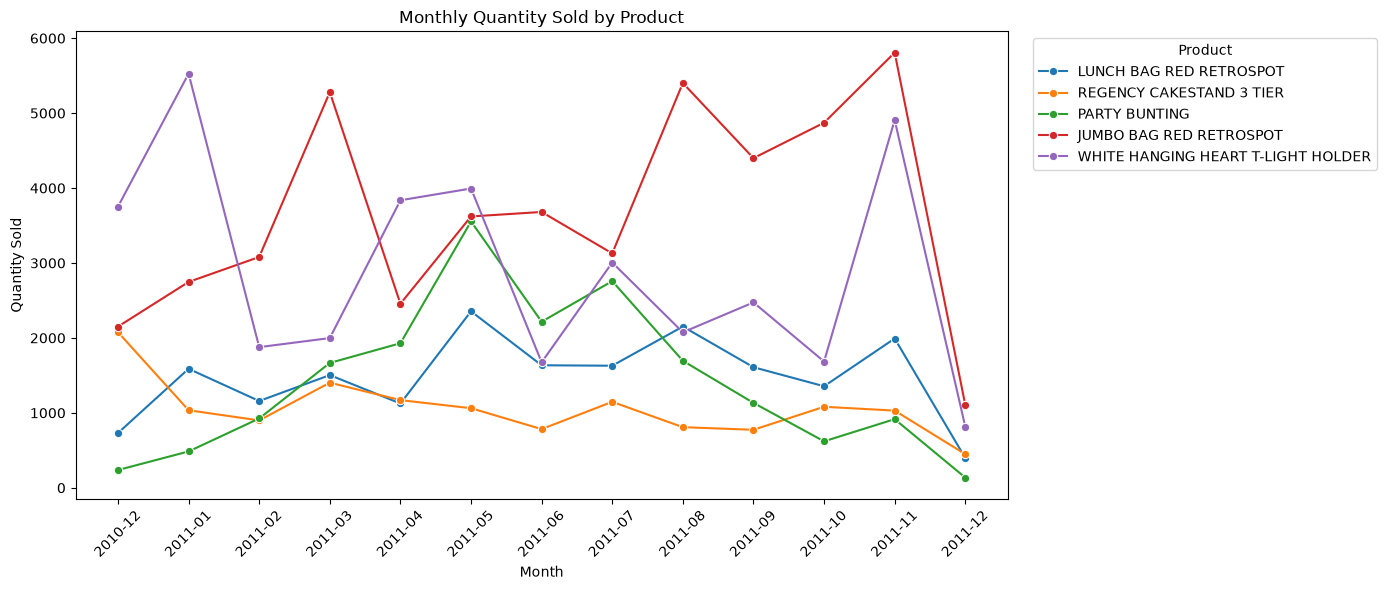

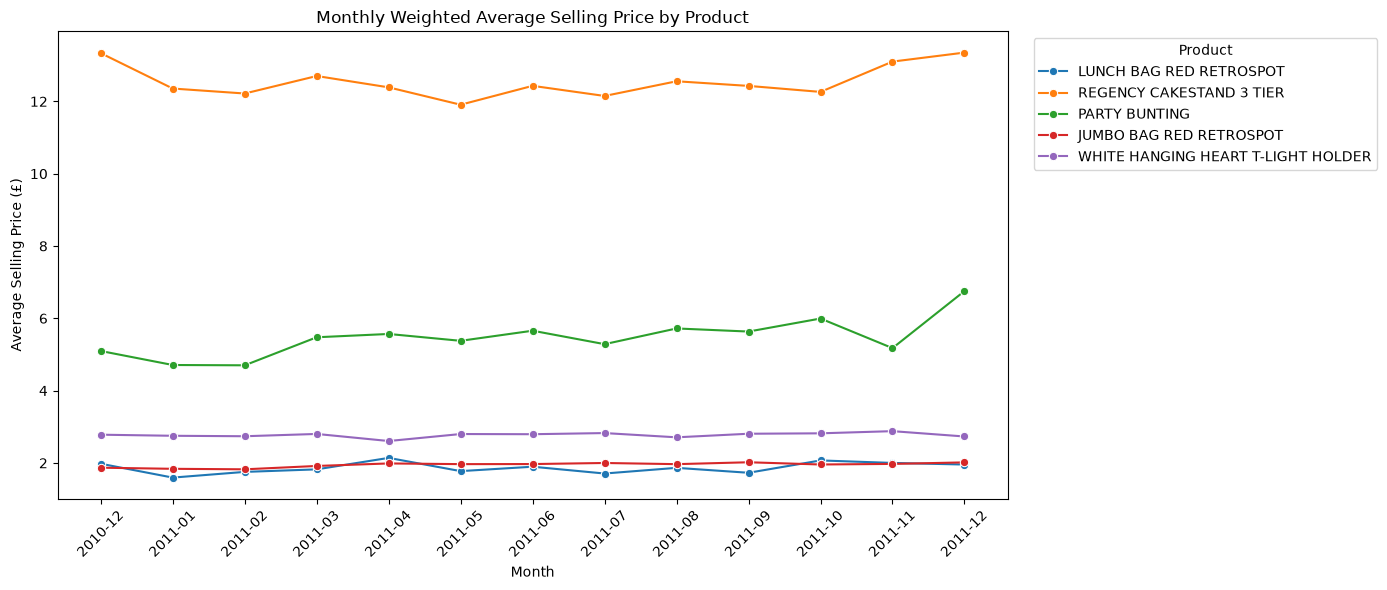

In [12]:
# Prepare monthly trends
monthly_product_analysis["Month"] = (
    monthly_product_analysis["InvoiceDate"].dt.strftime("%Y-%m")
)

# Chart 1: Monthly quantity sold
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_product_analysis,
    x="Month",
    y="quantity_sold",
    hue="Description",
    marker="o"
)

plt.title("Monthly Quantity Sold by Product")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.legend(title="Product", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


# Chart 2: Monthly weighted average selling price
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_product_analysis,
    x="Month",
    y="weighted_average_price",
    hue="Description",
    marker="o"
)

plt.title("Monthly Weighted Average Selling Price by Product")
plt.xlabel("Month")
plt.ylabel("Average Selling Price (£)")
plt.xticks(rotation=45)
plt.legend(title="Product", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

## 4. Price–quantity correlation

Pearson correlations are calculated separately for each selected product using monthly weighted-average price and monthly quantity. The p-values are used as descriptive tests of linear association. The number of monthly observations is small, so these estimates may be imprecise and sensitive to individual months.

In [13]:
price_quantity_correlation = (
    monthly_product_analysis
    .groupby(["StockCode", "Description"])
    .apply(
        lambda group: group["weighted_average_price"].corr(
            group["quantity_sold"]
        ),
        include_groups=False
    )
    .reset_index(name="price_quantity_correlation")
)

display(price_quantity_correlation.round(3))

,StockCode,Description,price_quantity_correlation
0,20725,LUNCH BAG RED RETROSPOT,-0.339
1,22423,REGENCY CAKESTAND 3 TIER,0.196
2,47566,PARTY BUNTING,-0.092
3,85099B,JUMBO BAG RED RETROSPOT,0.133
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.081


In [14]:
from scipy.stats import pearsonr

correlation_results = []

for (code, description), group in monthly_product_analysis.groupby(
    ["StockCode", "Description"]
):
    r, p = pearsonr(
        group["weighted_average_price"],
        group["quantity_sold"]
    )

    correlation_results.append({
        "StockCode": code,
        "Description": description,
        "Correlation": r,
        "P_value": p
    })

correlation_results = pd.DataFrame(correlation_results)

display(correlation_results.round(4))

,StockCode,Description,Correlation,P_value
0,20725,LUNCH BAG RED RETROSPOT,-0.3388,0.2575
1,22423,REGENCY CAKESTAND 3 TIER,0.1956,0.5219
2,47566,PARTY BUNTING,-0.0916,0.7660
3,85099B,JUMBO BAG RED RETROSPOT,0.1329,0.6652
4,85123A,WHITE HANGING HEART T-LIGHT HOLDER,0.0809,0.7928


## 5. Regression analysis

The notebook estimates a log-quantity/log-weighted-price regression with product and calendar-month fixed effects. The price coefficient is an observational conditional association in this aggregated panel. It must not be interpreted as a causal price elasticity: prices were not randomly assigned, and unobserved demand factors may influence both prices and quantities.

In [15]:
# Estimate an observational association, not a causal price elasticity.
import numpy as np
import pandas as pd
from scipy.stats import t

analysis_df = monthly_product_analysis.copy()

# Log transformations
analysis_df = analysis_df[
    (analysis_df["quantity_sold"] > 0) &
    (analysis_df["weighted_average_price"] > 0)
].copy()

analysis_df["log_quantity"] = np.log(analysis_df["quantity_sold"])
analysis_df["log_price"] = np.log(
    analysis_df["weighted_average_price"]
)

# Product and calendar-month fixed effects
product_dummies = pd.get_dummies(
    analysis_df["StockCode"], drop_first=True, dtype=float
)

month_dummies = pd.get_dummies(
    analysis_df["InvoiceDate"], drop_first=True, dtype=float
)

X = np.column_stack([
    np.ones(len(analysis_df)),
    analysis_df["log_price"].to_numpy(),
    product_dummies.to_numpy(),
    month_dummies.to_numpy()
])

y = analysis_df["log_quantity"].to_numpy()

# Estimate regression
coefficients, _, _, _ = np.linalg.lstsq(X, y, rcond=None)

residuals = y - X @ coefficients
n, k = X.shape
degrees_of_freedom = n - k

residual_variance = (residuals @ residuals) / degrees_of_freedom
covariance = residual_variance * np.linalg.inv(X.T @ X)

price_coefficient = coefficients[1]
standard_error = np.sqrt(covariance[1, 1])

t_statistic = price_coefficient / standard_error
p_value = 2 * t.sf(abs(t_statistic), degrees_of_freedom)

print("Observations:", n)
print("Degrees of freedom:", degrees_of_freedom)
print("Price coefficient:", round(price_coefficient, 4))
print("Standard error:", round(standard_error, 4))
print("T-statistic:", round(t_statistic, 4))
print("P-value:", round(p_value, 4))

Observations: 65
Degrees of freedom: 47
Price coefficient: 0.3691
Standard error: 1.2321
T-statistic: 0.2995
P-value: 0.7658


## 6. Data-quality checks and descriptive distributions

The following cells check duplicates, missing values, invalid quantities and prices, revenue consistency, date coverage, and the distributions of quantities and unit prices. Missing CustomerID values do not invalidate the product-level transaction totals, but they limit customer-level analyses.

In [16]:
# Final data-quality validation
print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum())

print("\nInvalid quantities:", (df["Quantity"] <= 0).sum())
print("Invalid prices:", (df["UnitPrice"] <= 0).sum())

revenue_difference = (
    df["Revenue"] - df["Quantity"] * df["UnitPrice"]
).abs()

print(
    "Revenue calculation errors:",
    (revenue_difference > 0.000001).sum()
)

print("\nDate range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

Dataset shape: (521755, 9)
Duplicate rows: 0

Missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     131420
Country             0
Revenue             0
dtype: int64

Invalid quantities: 0
Invalid prices: 0
Revenue calculation errors: 0

Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [17]:
print("Quantity distribution:")
display(df["Quantity"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nUnit price distribution:")
display(df["UnitPrice"].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99, 0.999]
))

print("\nHighest quantity transactions:")
display(
    df.nlargest(10, "Quantity")[
        ["StockCode", "Description", "Quantity", "UnitPrice", "Revenue"]
    ]
)

print("\nHighest price transactions:")
display(
    df.nlargest(10, "UnitPrice")[
        ["StockCode", "Description", "Quantity", "UnitPrice", "Revenue"]
    ]
)

Quantity distribution:


count    521755.000000
mean         10.307374
std          37.481423
min           1.000000
50%           4.000000
90%          24.000000
95%          30.000000
99%         100.000000
99.9%       432.000000
max        4800.000000
Name: Quantity, dtype: float64


Unit price distribution:


count    521755.000000
mean          3.272035
std           4.378718
min           0.001000
50%           2.080000
90%           7.620000
95%           9.950000
99%          16.630000
99.9%        33.290000
max         649.500000
Name: UnitPrice, dtype: float64


Highest quantity transactions:


,StockCode,Description,Quantity,UnitPrice,Revenue
405660,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00
198191,22197,SMALL POPCORN HOLDER,4300,0.72,3096.00
93680,22053,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92
260460,18007,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16
50625,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
417433,16014,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00
4775,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40
280135,84879,ASSORTED COLOUR BIRD ORNAMENT,2880,1.45,4176.00
193434,21977,PACK OF 60 PINK PAISLEY CAKE CASES,2700,0.42,1134.00
77636,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2592,0.21,544.32



Highest price transactions:


,StockCode,Description,Quantity,UnitPrice,Revenue
214118,22502,PICNIC BASKET WICKER 60 PIECES,60,649.5,38970.0
214119,22502,PICNIC BASKET WICKER 60 PIECES,1,649.5,649.5
4819,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
31137,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
49603,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
79616,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0
114330,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0
128891,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0
164531,22656,VINTAGE BLUE KITCHEN CABINET,1,295.0,295.0
197856,22655,VINTAGE RED KITCHEN CABINET,1,295.0,295.0


## 7. Findings, limitations, and conclusion

### Findings

- The prepared product-sales dataset currently contains 521,755 records.
- The five selected products show different monthly price and quantity patterns.
- The product-level correlations and the fixed-effects regression should be interpreted using their reported p-values and uncertainty; a positive or negative coefficient alone does not establish a reliable relationship.

### Limitations

- The data are observational, not a randomized pricing experiment.
- Monthly aggregation produces a small number of observations for each selected product.
- Seasonality, promotions, product mix, stock availability, and other unobserved factors may affect both price and demand.
- The dataset ends on 9 December 2011, so December 2011 is incomplete.
- The selected five products are not necessarily representative of the full catalogue.

### Conclusion

This EDA describes historical sales and price–quantity associations for five products. It does not provide sufficient evidence to recommend a causal price change. Any pricing-policy conclusions in this project must be evaluated separately using an appropriate causal design or clearly labelled synthetic experiments.